# Analytical Verification and Grid Convergence
**GPGN 436 — Underground Tunnel Electrical Resistivity Simulator**  
Molly Bilhartz · Step 4

This notebook imports the **same `solve_conductivity` function used by the Panel
application**. No verification-only PDE solver is constructed. Use **Restart Kernel
and Run All Cells** from the repository root. Saved tables and inline figures can
be read without running a server.

## 1. Purpose of numerical verification
Verification asks: *Does the code solve the specified mathematical equations
accurately?* We compare with a known exact solution and measure what happens when
the mesh is refined. This is different from **validation**, which asks whether
these equations and assumptions reproduce observations from a real mine survey.
No field-data validation is claimed here.

The homogeneous linear solution is an important regression test, but this stencil
reproduces a linear field up to roundoff. Its tiny error cannot demonstrate an
observed convergence order. We therefore choose smooth **variable conductivity**
and a curved, logarithmic potential profile.

**Course-instructions review:** this notebook was checked against Section 4
(Numerical verification), Section 6 (GitHub submission), and the verification
assessment in Section 8 of *GPGN 436/536 — Final Project Instructions and Grading
Policy*, Fall 2026, supplied by the course instructor. The checklist in Section 9
connects the requirements to the evidence here.

## 2. Governing PDE and physical interpretation
We solve steady, isotropic DC conduction in a rectangle $0\le x\le L$,
$0\le z\le H$, with depth $z$ positive downward:

$$\nabla\cdot(\sigma\nabla V)=0,\qquad \mathbf J=-\sigma\nabla V.$$

Here $V$ is potential (V), $\sigma$ conductivity (S/m), and $\mathbf J$ current
density (A/m²). The PDE expresses conservation of electric current with no
interior sources. Positive conductivity is required; resistivity is $1/\sigma$
in Ω·m. Integrating current density along a boundary gives current per unit
out-of-plane thickness (A/m) in this 2D model.

This is a **steady elliptic boundary-value problem**, not a time-dependent
simulation. No initial condition is prescribed, and no time-step parameter or
time-refinement study applies. Fixed side potentials and insulated top/bottom
faces define the boundary-value problem.

## 3. Analytical solution and boundary conditions
Choose $\sigma_0>0$ and $\beta>-1$, $\beta\ne0$:

$$\sigma(x)=\sigma_0\left(1+\beta\frac{x}{L}\right).$$

The minimum of $1+\beta x/L$ over the domain is $\min(1,1+\beta)>0$.
For a solution independent of depth, the PDE reduces to

$$\frac{d}{dx}\left(\sigma(x)\frac{dV}{dx}\right)=0.$$

Thus $\sigma V'=C$. Integrating $V'=C/[\sigma_0(1+\beta x/L)]$
and imposing $V(0)=V_L$, $V(L)=V_R$ gives

$$V(x)=V_L+(V_R-V_L)\frac{\ln(1+\beta x/L)}{\ln(1+\beta)}.$$

**Direct substitution:**

$$\frac{dV}{dx}=\frac{(V_R-V_L)\beta}
 {L\ln(1+\beta)(1+\beta x/L)},\qquad
 \sigma\frac{dV}{dx}=\frac{\sigma_0(V_R-V_L)\beta}{L\ln(1+\beta)}=C.$$

The derivative of this constant is zero, and all $z$ derivatives are zero, so the
full 2D source-free PDE is satisfied. At $x=0$ the logarithmic fraction is 0; at
$x=L$ it is 1. At the top and bottom, $\partial V/\partial z=0$, so
$\mathbf J\cdot\mathbf n=0$. These are **exactly the fixed side voltages and
insulating top/bottom conditions used by the existing solver**. For positive
conductivity the fixed side potentials also remove the arbitrary potential offset.

The exact current density is constant:

$$J_x=-\frac{\sigma_0(V_R-V_L)\beta}{L\ln(1+\beta)},\qquad J_z=0.$$

With $V_L>V_R$, current flows rightward. The formula is undefined at $\beta=0$,
but its limit is the homogeneous linear solution. We exclude that case here
and use `log1p` to evaluate $\ln(1+q)$ accurately.

## 4. Numerical model setup
The physical model is fixed across all meshes: $L=100$ m, $H=50$ m,
$\sigma_0=0.01$ S/m, $\beta=2$, $V_L=1$ V, and $V_R=0$ V.
Conductivity varies smoothly from 0.01 to 0.03 S/m at the physical sides.

The existing solver stores one potential per **cell center**, indexed `[iz, ix]`.
Its conservative finite differences balance shared-face currents. Interior face
conductivities are harmonic averages; a fixed-voltage boundary is half a cell
from its adjacent center. Top/bottom faces contribute zero flux. We supply the
conductivity sampled at the same cell centers and leave all numerical assembly
and solving to the production module.

In [1]:
from pathlib import Path
import hashlib
import inspect
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Markdown, display

%matplotlib inline

ROOT = Path.cwd().resolve()
if not (ROOT / "tunnel_resistivity" / "solver.py").is_file():
    raise RuntimeError("Run this notebook from the repository root.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from tunnel_resistivity.solver import solve_conductivity

solver_file = Path(inspect.getsourcefile(solve_conductivity)).resolve()
assert solver_file == ROOT / "tunnel_resistivity" / "solver.py"
print("Production solver:", solver_file.relative_to(ROOT))
print("Solver SHA256:", hashlib.sha256(solver_file.read_bytes()).hexdigest())
print("Python", platform.python_version(), "| NumPy", np.__version__, "| SciPy", scipy.__version__)

Production solver: tunnel_resistivity/solver.py
Solver SHA256: 97acd2877cea4b70ed3754cac387c2cba3f7e8fc14adf0a5e2e2c18798142556
Python 3.12.14 | NumPy 2.3.5 | SciPy 1.17.0


In [2]:
L, H = 100.0, 50.0          # m
SIGMA0, BETA = 0.01, 2.0   # S/m, dimensionless
VL, VR = 1.0, 0.0          # V
assert SIGMA0 > 0 and BETA > -1 and BETA != 0
assert VL != VR             # Needed for the relative-error normalization below.


def exact_potential(x):
    return VL + (VR - VL) * np.log1p(BETA * x / L) / np.log1p(BETA)


JX_EXACT = -SIGMA0 * (VR - VL) * BETA / (L * np.log1p(BETA))
print(f"Analytical Jx = {JX_EXACT:.10e} A/m²; Jz = 0")
print(f"Analytical total current = {JX_EXACT * H:.10e} A/m thickness")
np.testing.assert_allclose(exact_potential(np.array([0.0, L])), [VL, VR], atol=1e-14)

Analytical Jx = 1.8204784533e-04 A/m²; Jz = 0
Analytical total current = 9.1023922663e-03 A/m thickness


In [3]:
def show_table(headers, rows):
    """Display a small Markdown table without another numerical dependency."""
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def run_case(nx, nz):
    """Sample sigma and call the actual solver; then evaluate exact V at its centers."""
    dx, dz = L / nx, H / nz
    x_centers = (np.arange(nx) + 0.5) * dx
    sigma_x = SIGMA0 * (1 + BETA * x_centers / L)
    sigma = np.broadcast_to(sigma_x, (nz, nx)).copy()
    assert np.all(np.isfinite(sigma)) and np.all(sigma > 0)
    model = solve_conductivity(sigma, width=L, height=H,
                               left_potential=VL, right_potential=VR)
    exact = np.broadcast_to(exact_potential(model.x), model.potential.shape)
    error = model.potential - exact
    rmse = float(np.sqrt(np.mean(error**2)))
    return {"nx": nx, "nz": nz, "dx": dx, "dz": dz, "h": max(dx, dz),
            "model": model, "exact": exact, "error": error,
            "max_error": float(np.max(np.abs(error))), "rmse": rmse,
            "relative_rmse": rmse / abs(VL - VR)}


example = run_case(80, 40)
m = example["model"]
print(f"Representative grid: {len(m.x)} × {len(m.z)} cells; dx={m.dx:g}, dz={m.dz:g} m")
print(f"Sampled conductivity: {m.conductivity.min():.6f} to {m.conductivity.max():.6f} S/m")

Representative grid: 80 × 40 cells; dx=1.25, dz=1.25 m
Sampled conductivity: 0.010125 to 0.029875 S/m


## 5. Comparison of analytical and numerical solutions
Both maps and the error use the solver's actual cell-center coordinates. Cell
edges are used only to draw each cell's footprint. The selected profile is the
row nearest mid-depth; the exact solution is independent of depth. It is curved,
so a linear potential cannot pass this comparison.

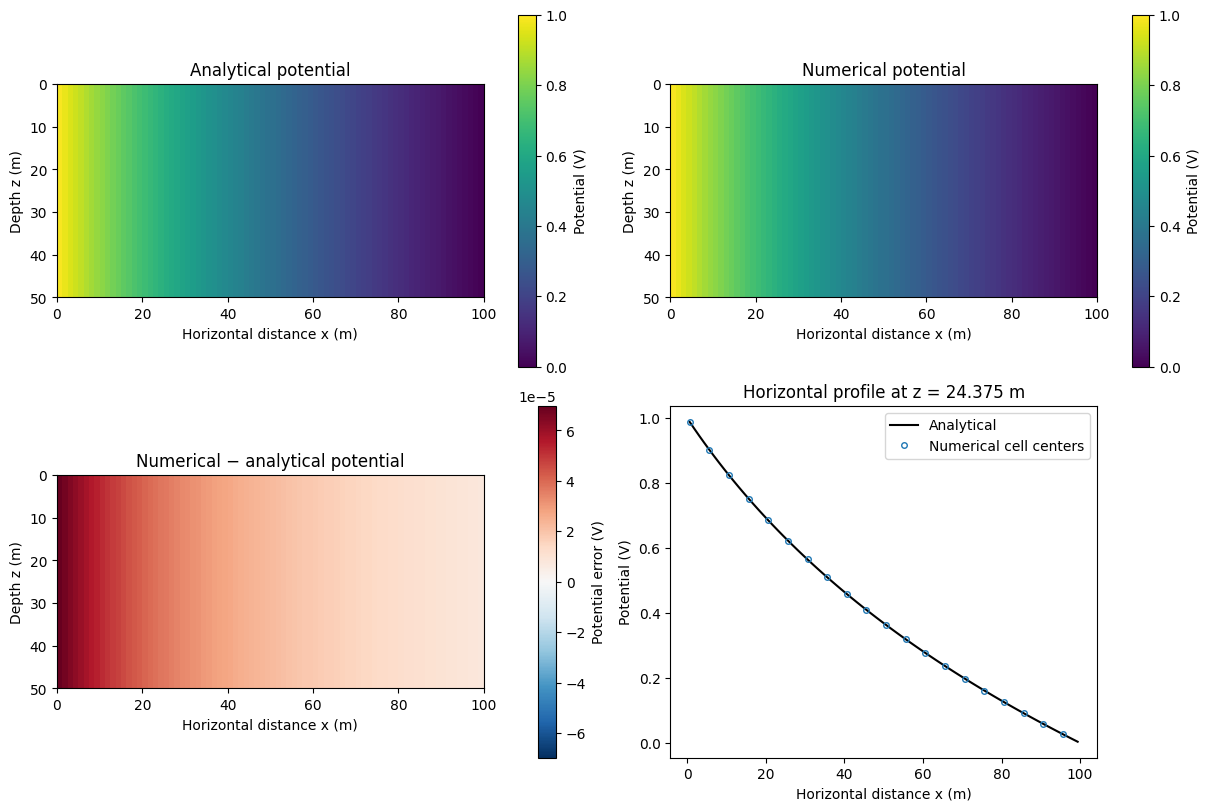

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
xedges = np.linspace(0, L, example["nx"] + 1)
zedges = np.linspace(0, H, example["nz"] + 1)
error_limit = max(example["max_error"], np.finfo(float).eps)
for ax, field, title, cmap, low, high in (
    (axes[0, 0], example["exact"], "Analytical potential", "viridis", min(VL, VR), max(VL, VR)),
    (axes[0, 1], m.potential, "Numerical potential", "viridis", min(VL, VR), max(VL, VR)),
    (axes[1, 0], example["error"], "Numerical − analytical potential", "RdBu_r", -error_limit, error_limit),
):
    image = ax.pcolormesh(xedges, zedges, field, shading="flat", cmap=cmap, vmin=low, vmax=high)
    ax.set(xlabel="Horizontal distance x (m)", ylabel="Depth z (m)",
           title=title, xlim=(0, L), ylim=(H, 0))
    ax.set_aspect("equal")
    fig.colorbar(image, ax=ax, label="Potential (V)" if "−" not in title else "Potential error (V)")

iz = int(np.argmin(np.abs(m.z - H / 2)))
axes[1, 1].plot(m.x, example["exact"][iz], label="Analytical", color="black")
axes[1, 1].plot(m.x, m.potential[iz], "o", markevery=4, markersize=4,
                fillstyle="none", label="Numerical cell centers")
axes[1, 1].set(xlabel="Horizontal distance x (m)", ylabel="Potential (V)",
               title=f"Horizontal profile at z = {m.z[iz]:.3f} m")
axes[1, 1].legend()
plt.show()

## 6. Quantitative error calculations
For $N=n_xn_z$ cell centers, let $e_k=V_k^{num}-V_k^{exact}$. We report

$$E_\infty=\max_k|e_k|,\qquad
E_{RMS}=\sqrt{\frac{1}{N}\sum_{k=1}^N e_k^2},\qquad
E_{rel}=\frac{E_{RMS}}{|V_L-V_R|}.$$

Maximum error finds the worst cell; RMSE measures typical error over the domain.
The relative error is dimensionless and normalized by the **imposed voltage
span**, not by local potential. Dividing by local $V$ near the zero-voltage side
would exaggerate the error and is not used. The table also gives $100E_{rel}$ as
a percentage. Uniform cell areas make this RMSE equivalent to an area-weighted
RMS on each grid. A small linear-system residual alone would not measure these
errors: it only checks how closely the discrete equations are solved.

In [5]:
show_table(["Grid", "Max absolute error (V)", "RMSE (V)", "Relative RMSE", "Relative RMSE (%)"],
           [[f"{example['nx']} × {example['nz']}", f"{example['max_error']:.8e}",
             f"{example['rmse']:.8e}", f"{example['relative_rmse']:.8e}",
             f"{100 * example['relative_rmse']:.6f}"]])

| Grid | Max absolute error (V) | RMSE (V) | Relative RMSE | Relative RMSE (%) |
| --- | --- | --- | --- | --- |
| 80 × 40 | 6.97069251e-05 | 3.15984775e-05 | 3.15984775e-05 | 0.003160 |

## 7. Grid-refinement and convergence analysis
We halve both $\Delta x$ and $\Delta z$ at each refinement. Dimensions,
conductivity function, and boundary conditions remain fixed; the conductivity
function is resampled at each mesh's centers. This does not move or resize any
physical feature.

The observed order between consecutive grids is

$$p=\frac{\ln(E_{coarse}/E_{fine})}{\ln(h_{coarse}/h_{fine})},\qquad
h=\max(\Delta x,\Delta z).$$

We calculate this from the measured errors separately for RMSE and maximum error.
No order is prescribed or used to modify a result. The first grid has no preceding
pair, so its observed order is left blank. The $h^2$ line in the plot is only a
visual guide anchored at the coarsest RMSE; it is not a replacement for the data.

| Grid | dx (m) | dz (m) | Max error (V) | RMSE (V) | Relative RMSE | p (RMSE) | p (max) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 20 × 10 | 5 | 5 | 1.05140696e-03 | 5.04468369e-04 | 5.04468369e-04 | — | — |
| 40 × 20 | 2.5 | 2.5 | 2.73357464e-04 | 1.26338251e-04 | 1.26338251e-04 | 1.997472 | 1.943461 |
| 80 × 40 | 1.25 | 1.25 | 6.97069251e-05 | 3.15984775e-05 | 3.15984775e-05 | 1.999365 | 1.971415 |
| 160 × 80 | 0.625 | 0.625 | 1.76012134e-05 | 7.90049055e-06 | 7.90049055e-06 | 1.999841 | 1.985627 |

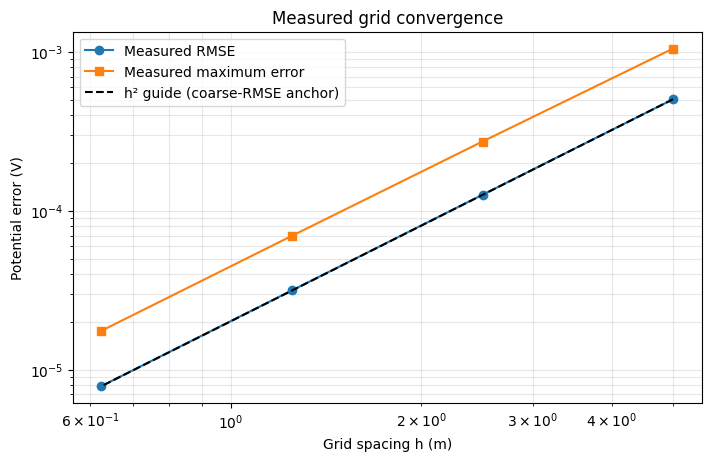

In [6]:
grids = [(20, 10), (40, 20), (80, 40), (160, 80)]
results = [example if (nx, nz) == (80, 40) else run_case(nx, nz) for nx, nz in grids]
orders_rmse, orders_max = [], []
rows = []
for i, result in enumerate(results):
    if i == 0:
        p_rmse = p_max = "—"
    else:
        previous = results[i - 1]
        ratio = np.log(previous["h"] / result["h"])
        p_rmse = np.log(previous["rmse"] / result["rmse"]) / ratio
        p_max = np.log(previous["max_error"] / result["max_error"]) / ratio
        orders_rmse.append(float(p_rmse))
        orders_max.append(float(p_max))
        p_rmse, p_max = f"{p_rmse:.6f}", f"{p_max:.6f}"
    rows.append([f"{result['nx']} × {result['nz']}", f"{result['dx']:g}", f"{result['dz']:g}",
                 f"{result['max_error']:.8e}", f"{result['rmse']:.8e}",
                 f"{result['relative_rmse']:.8e}", p_rmse, p_max])
show_table(["Grid", "dx (m)", "dz (m)", "Max error (V)", "RMSE (V)",
            "Relative RMSE", "p (RMSE)", "p (max)"], rows)

hs = np.array([r["h"] for r in results])
rmses = np.array([r["rmse"] for r in results])
max_errors = np.array([r["max_error"] for r in results])
assert np.all(np.isfinite(rmses)) and np.all(rmses > 0)
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.loglog(hs, rmses, "o-", label="Measured RMSE")
ax.loglog(hs, max_errors, "s-", label="Measured maximum error")
ax.loglog(hs, rmses[0] * (hs / hs[0])**2, "k--", label="h² guide (coarse-RMSE anchor)")
ax.set(xlabel="Grid spacing h (m)", ylabel="Potential error (V)", title="Measured grid convergence")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

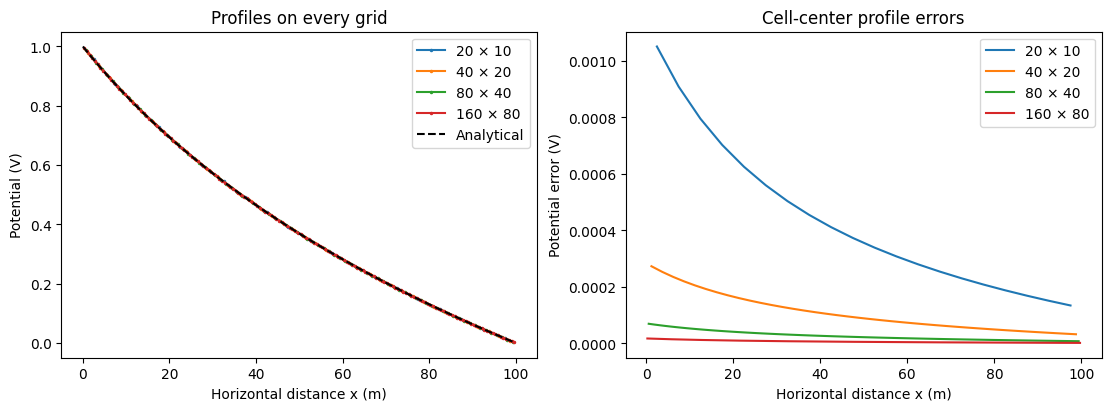

**Measured behavior:** both errors decrease on every refinement: **True**. Successive RMSE orders range from **1.997472** to **1.999841**. The orders are calculated from the errors, not imposed.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for result in results:
    model = result["model"]
    iz = len(model.z) // 2
    label = f"{result['nx']} × {result['nz']}"
    axes[0].plot(model.x, model.potential[iz], ".-", label=label, markersize=3)
    axes[1].plot(model.x, result["error"][iz], label=label)
xfine = np.linspace(0, L, 500)
axes[0].plot(xfine, exact_potential(xfine), "k--", label="Analytical")
axes[0].set(xlabel="Horizontal distance x (m)", ylabel="Potential (V)", title="Profiles on every grid")
axes[1].set(xlabel="Horizontal distance x (m)", ylabel="Potential error (V)", title="Cell-center profile errors")
for ax in axes:
    ax.legend()
plt.show()

monotone = bool(np.all(np.diff(rmses) < 0) and np.all(np.diff(max_errors) < 0))
display(Markdown(
    f"**Measured behavior:** both errors decrease on every refinement: **{monotone}**. "
    f"Successive RMSE orders range from **{min(orders_rmse):.6f}** to "
    f"**{max(orders_rmse):.6f}**. The orders are calculated from the errors, not imposed."
))

### Additional verification: current, conservation, and boundaries
The exact $J_x$ is constant at every face, with $J_z=0$. We compare the returned
**face currents**, not cell-center plotting averages. Relative current error uses
$|J_x^{exact}|$ as its normalization.

For each cell we compute net outward current per unit thickness,
$Q=(J_E-J_W)\Delta z+(J_S-J_N)\Delta x$. We normalize the largest $|Q|$ by the
largest individual face-current magnitude. Global imbalance is
$|I_{left}-I_{right}|/|I_{left}|$. Insulated faces should have exactly zero
normal current; tiny interior vertical currents can result from roundoff.

For the implemented discrete side condition, reconstruct the boundary values:
$V_L^{rec}=V_{first}+J_{left}\Delta x/(2\sigma_{first})$ and
$V_R^{rec}=V_{last}-J_{right}\Delta x/(2\sigma_{last})$.
These reconstructions check the half-cell conditions. Simply requiring the
first and last **cell centers** to equal the side voltages would be incorrect.
They do not replace the separate comparison with the exact current.

In [8]:
checks = []
for result in results:
    model = result["model"]
    sigma = model.conductivity
    jx_error = float(np.max(np.abs(model.jx - JX_EXACT)))
    jz_max = float(np.max(np.abs(model.jz)))
    current_in = float(np.sum(model.jx[:, 0]) * model.dz)
    current_out = float(np.sum(model.jx[:, -1]) * model.dz)
    imbalance = abs(current_in - current_out) / abs(current_in)
    net = np.diff(model.jx, axis=1) * model.dz + np.diff(model.jz, axis=0) * model.dx
    face_scale = max(np.max(np.abs(model.jx)) * model.dz, np.max(np.abs(model.jz)) * model.dx)
    local_imbalance = float(np.max(np.abs(net)) / face_scale)
    left_reconstructed = model.potential[:, 0] + model.jx[:, 0] * model.dx / (2 * sigma[:, 0])
    right_reconstructed = model.potential[:, -1] - model.jx[:, -1] * model.dx / (2 * sigma[:, -1])
    boundary_error = float(max(np.max(np.abs(left_reconstructed - VL)),
                               np.max(np.abs(right_reconstructed - VR))))
    checks.append({"jx_error": jx_error, "relative_jx_error": jx_error / abs(JX_EXACT),
                   "max_jz": jz_max, "global_imbalance": imbalance, "local_imbalance": local_imbalance,
                   "boundary_error": boundary_error, "residual": model.residual_inf})
    np.testing.assert_array_equal(model.jz[[0, -1], :], 0)
    assert jz_max / abs(JX_EXACT) < 1e-10
    assert imbalance < 1e-9 and local_imbalance < 1e-9
    assert boundary_error < 1e-12 and model.residual_inf < 1e-12
    assert np.all(np.isfinite(model.potential))
    assert model.potential.min() >= min(VL, VR) - 1e-10
    assert model.potential.max() <= max(VL, VR) + 1e-10

show_table(["Grid", "Max Jx error (A/m²)", "Relative Jx error", "Max abs Jz (A/m²)",
            "Global imbalance", "Local imbalance", "Boundary error (V)", "Residual (A/m)"],
           [[f"{r['nx']} × {r['nz']}", f"{c['jx_error']:.3e}", f"{c['relative_jx_error']:.3e}",
             f"{c['max_jz']:.3e}", f"{c['global_imbalance']:.3e}", f"{c['local_imbalance']:.3e}",
             f"{c['boundary_error']:.3e}", f"{c['residual']:.3e}"] for r, c in zip(results, checks)])
print("All displayed conservation, boundary, finiteness, and vertical-current checks passed.")

| Grid | Max Jx error (A/m²) | Relative Jx error | Max abs Jz (A/m²) | Global imbalance | Local imbalance | Boundary error (V) | Residual (A/m) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 20 × 10 | 6.127e-08 | 3.366e-04 | 1.288e-18 | 1.905e-15 | 1.704e-14 | 1.735e-18 | 1.561e-17 |
| 40 × 20 | 1.534e-08 | 8.425e-05 | 2.565e-18 | 1.124e-14 | 4.026e-14 | 1.735e-18 | 2.082e-17 |
| 80 × 40 | 3.835e-09 | 2.107e-05 | 7.949e-18 | 8.385e-14 | 1.466e-13 | 8.674e-19 | 2.776e-17 |
| 160 × 80 | 9.589e-10 | 5.267e-06 | 1.936e-17 | 3.061e-13 | 2.605e-13 | 4.337e-19 | 3.123e-17 |

All displayed conservation, boundary, finiteness, and vertical-current checks passed.


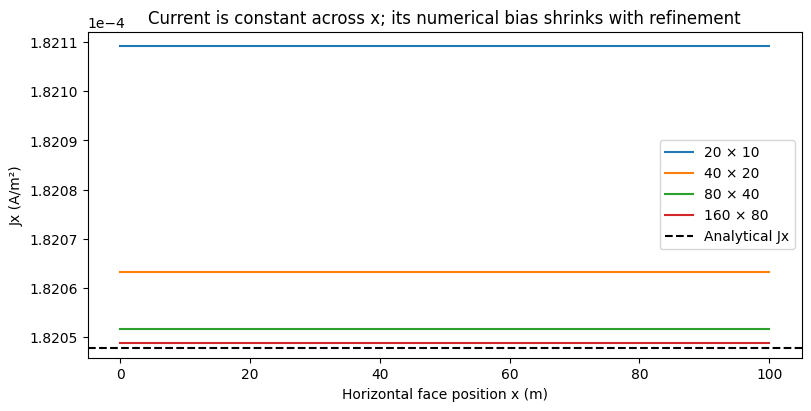

In [9]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for result in results:
    model = result["model"]
    face_x = np.linspace(0, L, result["nx"] + 1)
    ax.plot(face_x, model.jx[len(model.z)//2], label=f"{result['nx']} × {result['nz']}")
ax.axhline(JX_EXACT, color="black", linestyle="--", label="Analytical Jx")
ax.set(xlabel="Horizontal face position x (m)", ylabel="Jx (A/m²)",
       title="Current is constant across x; its numerical bias shrinks with refinement")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)
ax.legend()
plt.show()

## 8. Discussion of numerical limitations
For this smooth problem, the observed potential-error orders approach two. That
is consistent with central interior differences and a smooth conductivity field,
but the result is **measured here**, not guaranteed for every model. Harmonic face
averaging represents series resistance between sampled cell values. Even when
conductivity is linear in $x$, its reciprocal and potential are nonlinear, so
finite-spacing errors remain. At side boundaries, the half-cell resistance uses
the adjacent sampled conductivity rather than an exact integral through the
continuously varying medium. Boundary treatment contributes to the measured error.

If errors stopped decreasing, useful checks would include center-versus-edge
coordinates, coefficient sampling, side-boundary distances, and whether roundoff
or conditioning dominates. At very fine meshes roundoff can obscure an asymptotic
order. Different values of $\beta$, especially near $-1$, can require finer grids.

This is a 2D solve with an exact solution that varies only with $x$. It checks the
production assembly on several 2D meshes, coefficient interfaces, boundaries, and
flux conservation, but does not establish convergence for general solutions
varying strongly in both coordinates. The existing geometry/physics regressions
provide complementary checks, not a substitute for further analytical cases.

### Connection to the tunnel application
The Panel app and this notebook call the same variable-conductivity solver, so
these results support confidence in its numerical building blocks. They do not
remove the tunnel model's uncertainties:

- Circular interfaces are stair-stepped on a rectangular cell grid; grid changes
  can alter both area and interface shape, unlike this smooth verification case.
- Large conductivity contrasts may worsen conditioning and local flux accuracy.
- Side electrodes at fixed potential and insulated horizontal boundaries are
  simplified electrical boundary conditions; finite domain boundaries affect signals.
- A 2D cross-section assumes an indefinitely long tunnel and omits finite ends,
  geological complexity, anisotropy, and electrode contact effects.

Verification of equations is not validation against real geophysical field data.

## 9. Conclusions
The outputs below summarize this execution. To explain the verification in a
presentation: **derive constant $\sigma V'$, integrate to obtain the logarithm,
evaluate at cell centers, define the error normalization, then calculate the
observed order from error ratios.** Explain why small residuals alone are not
sufficient and why a smooth-medium result does not establish tunnel accuracy.

### Course requirement checklist and references

| PDF Section 4 requirement | Evidence in this notebook |
| --- | --- |
| Describe test problem and analytical solution | Sections 2–3: smooth conductivity and derivation by substitution |
| Matching physical parameters, initial and boundary conditions | Sections 3–4: fixed dimensions/coefficient/voltages, insulated top/bottom; no initial condition for this steady PDE |
| Run the same numerical simulation code independently of UI | Section 4 imports `tunnel_resistivity.solver.solve_conductivity` directly; no Panel import or alternate solver |
| Plots and a quantitative error measure | Sections 5–6: maps, profiles, maximum error, RMSE, voltage-span-normalized error |
| Error versus grid spacing and applicable time-step size | Section 7: four grids, log-log errors and observed orders; no time step for a steady solve |
| Explain agreement, discrepancies, and limitations | Sections 7–9: measured behavior, coefficient/boundary approximation, limitations and tunnel connection |
| Save executed plots and outputs for GitHub | This notebook retains inline figures, tables and execution counts; commit/upload the executed file without clearing its outputs |

These provide evidence for Section 8's **15-point analytical-verification** component;
meeting a grading rubric is ultimately assessed by the instructor. Section 6 also
requires the complete project on GitHub, a reproducible dependency file, README,
AI-use statement and references. Preparing this file does not upload it or establish
instructor access. This mathematical test requires no external data file.

**References:**

- Course instructor, *GPGN 436/536 — Final Project Instructions and Grading Policy*,
  Fall 2026, especially Sections 3, 4, 6 and 8 (user-supplied PDF).
- Project source: `tunnel_resistivity/solver.py` (the visible finite-difference
  assembly and SciPy sparse solve used by the application).
- The analytical solution was specified in the Step 4 request; its derivation is
  included in Section 3 rather than accepted without checking. No external solver
  or external numerical code was incorporated.
- AI assistance is disclosed in `AI_USE.md`. The student remains responsible for
  checking the work and explaining it independently during the presentation.

In [10]:
fine = results[-1]
display(Markdown(
    f"- Finest grid: **{fine['nx']} × {fine['nz']}** cells.\n"
    f"- Maximum potential error: **{fine['max_error']:.8e} V**.\n"
    f"- RMSE: **{fine['rmse']:.8e} V**, relative RMSE **{fine['relative_rmse']:.8e}** "
    f"(**{100*fine['relative_rmse']:.6f}%** of imposed voltage span).\n"
    f"- Successive measured RMSE orders: **{', '.join(f'{p:.6f}' for p in orders_rmse)}**.\n"
    f"- Finest-grid relative Jx error: **{checks[-1]['relative_jx_error']:.8e}**.\n"
    f"- All additional asserted checks completed successfully.\n"
    f"- The same production solver was used on every grid; no application method was changed.\n"
    f"- The Section 4 numerical-verification requirements are addressed; GitHub upload and instructor assessment remain separate."
))

- Finest grid: **160 × 80** cells.
- Maximum potential error: **1.76012134e-05 V**.
- RMSE: **7.90049055e-06 V**, relative RMSE **7.90049055e-06** (**0.000790%** of imposed voltage span).
- Successive measured RMSE orders: **1.997472, 1.999365, 1.999841**.
- Finest-grid relative Jx error: **5.26745623e-06**.
- All additional asserted checks completed successfully.
- The same production solver was used on every grid; no application method was changed.
- The Section 4 numerical-verification requirements are addressed; GitHub upload and instructor assessment remain separate.